#imports

In [38]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from matplotlib.pylab import rcParams
from sklearn.model_selection import train_test_split
df = pd.read_csv('/content/Social_Network_Ads.csv')
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


#data preprocessing

In [39]:
df['Gender']=df['Gender'].replace({'Male':1,'Female':0})
df.head()

/tmp/ipykernel_512/3665408947.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender']=df['Gender'].replace({'Male':1,'Female':0})


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,19,19000,0
1,15810944,1,35,20000,0
2,15668575,0,26,43000,0
3,15603246,0,27,57000,0
4,15804002,1,19,76000,0


In [40]:
X = df.iloc[:,0:4]
y = df.iloc[:,-1]

#train test split

In [41]:
x_train,x_test,y_train,y_test = train_test_split(X,y,random_state=2,test_size=0.2)

#decision tree object
#<font color='red'>max_depth = 4 <br>critrion=gini<br>splitter=random</font>


In [42]:
dtc = DecisionTreeClassifier(max_depth=4,criterion='gini',splitter='random',random_state=2)

#fit

In [43]:
dtc.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=4, random_state=2, splitter='random')

#ploting tree

[Text(0.4782608695652174, 0.9, 'x[3] <= 88075.801\ngini = 0.453\nsamples = 320\nvalue = [209, 111]'),
 Text(0.2391304347826087, 0.7, 'x[2] <= 54.287\ngini = 0.342\nsamples = 247\nvalue = [193, 54]'),
 Text(0.3586956521739131, 0.8, 'True  '),
 Text(0.08695652173913043, 0.5, 'x[2] <= 34.136\ngini = 0.282\nsamples = 230\nvalue = [191, 39]'),
 Text(0.043478260869565216, 0.3, 'gini = 0.0\nsamples = 93\nvalue = [93, 0]'),
 Text(0.13043478260869565, 0.3, 'x[2] <= 50.919\ngini = 0.407\nsamples = 137\nvalue = [98, 39]'),
 Text(0.08695652173913043, 0.1, 'gini = 0.377\nsamples = 131\nvalue = [98, 33]'),
 Text(0.17391304347826086, 0.1, 'gini = 0.0\nsamples = 6\nvalue = [0, 6]'),
 Text(0.391304347826087, 0.5, 'x[0] <= 15609433.17\ngini = 0.208\nsamples = 17\nvalue = [2, 15]'),
 Text(0.30434782608695654, 0.3, 'x[0] <= 15595419.329\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.2608695652173913, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.34782608695652173, 0.1, 'gini = 0.5\nsampl

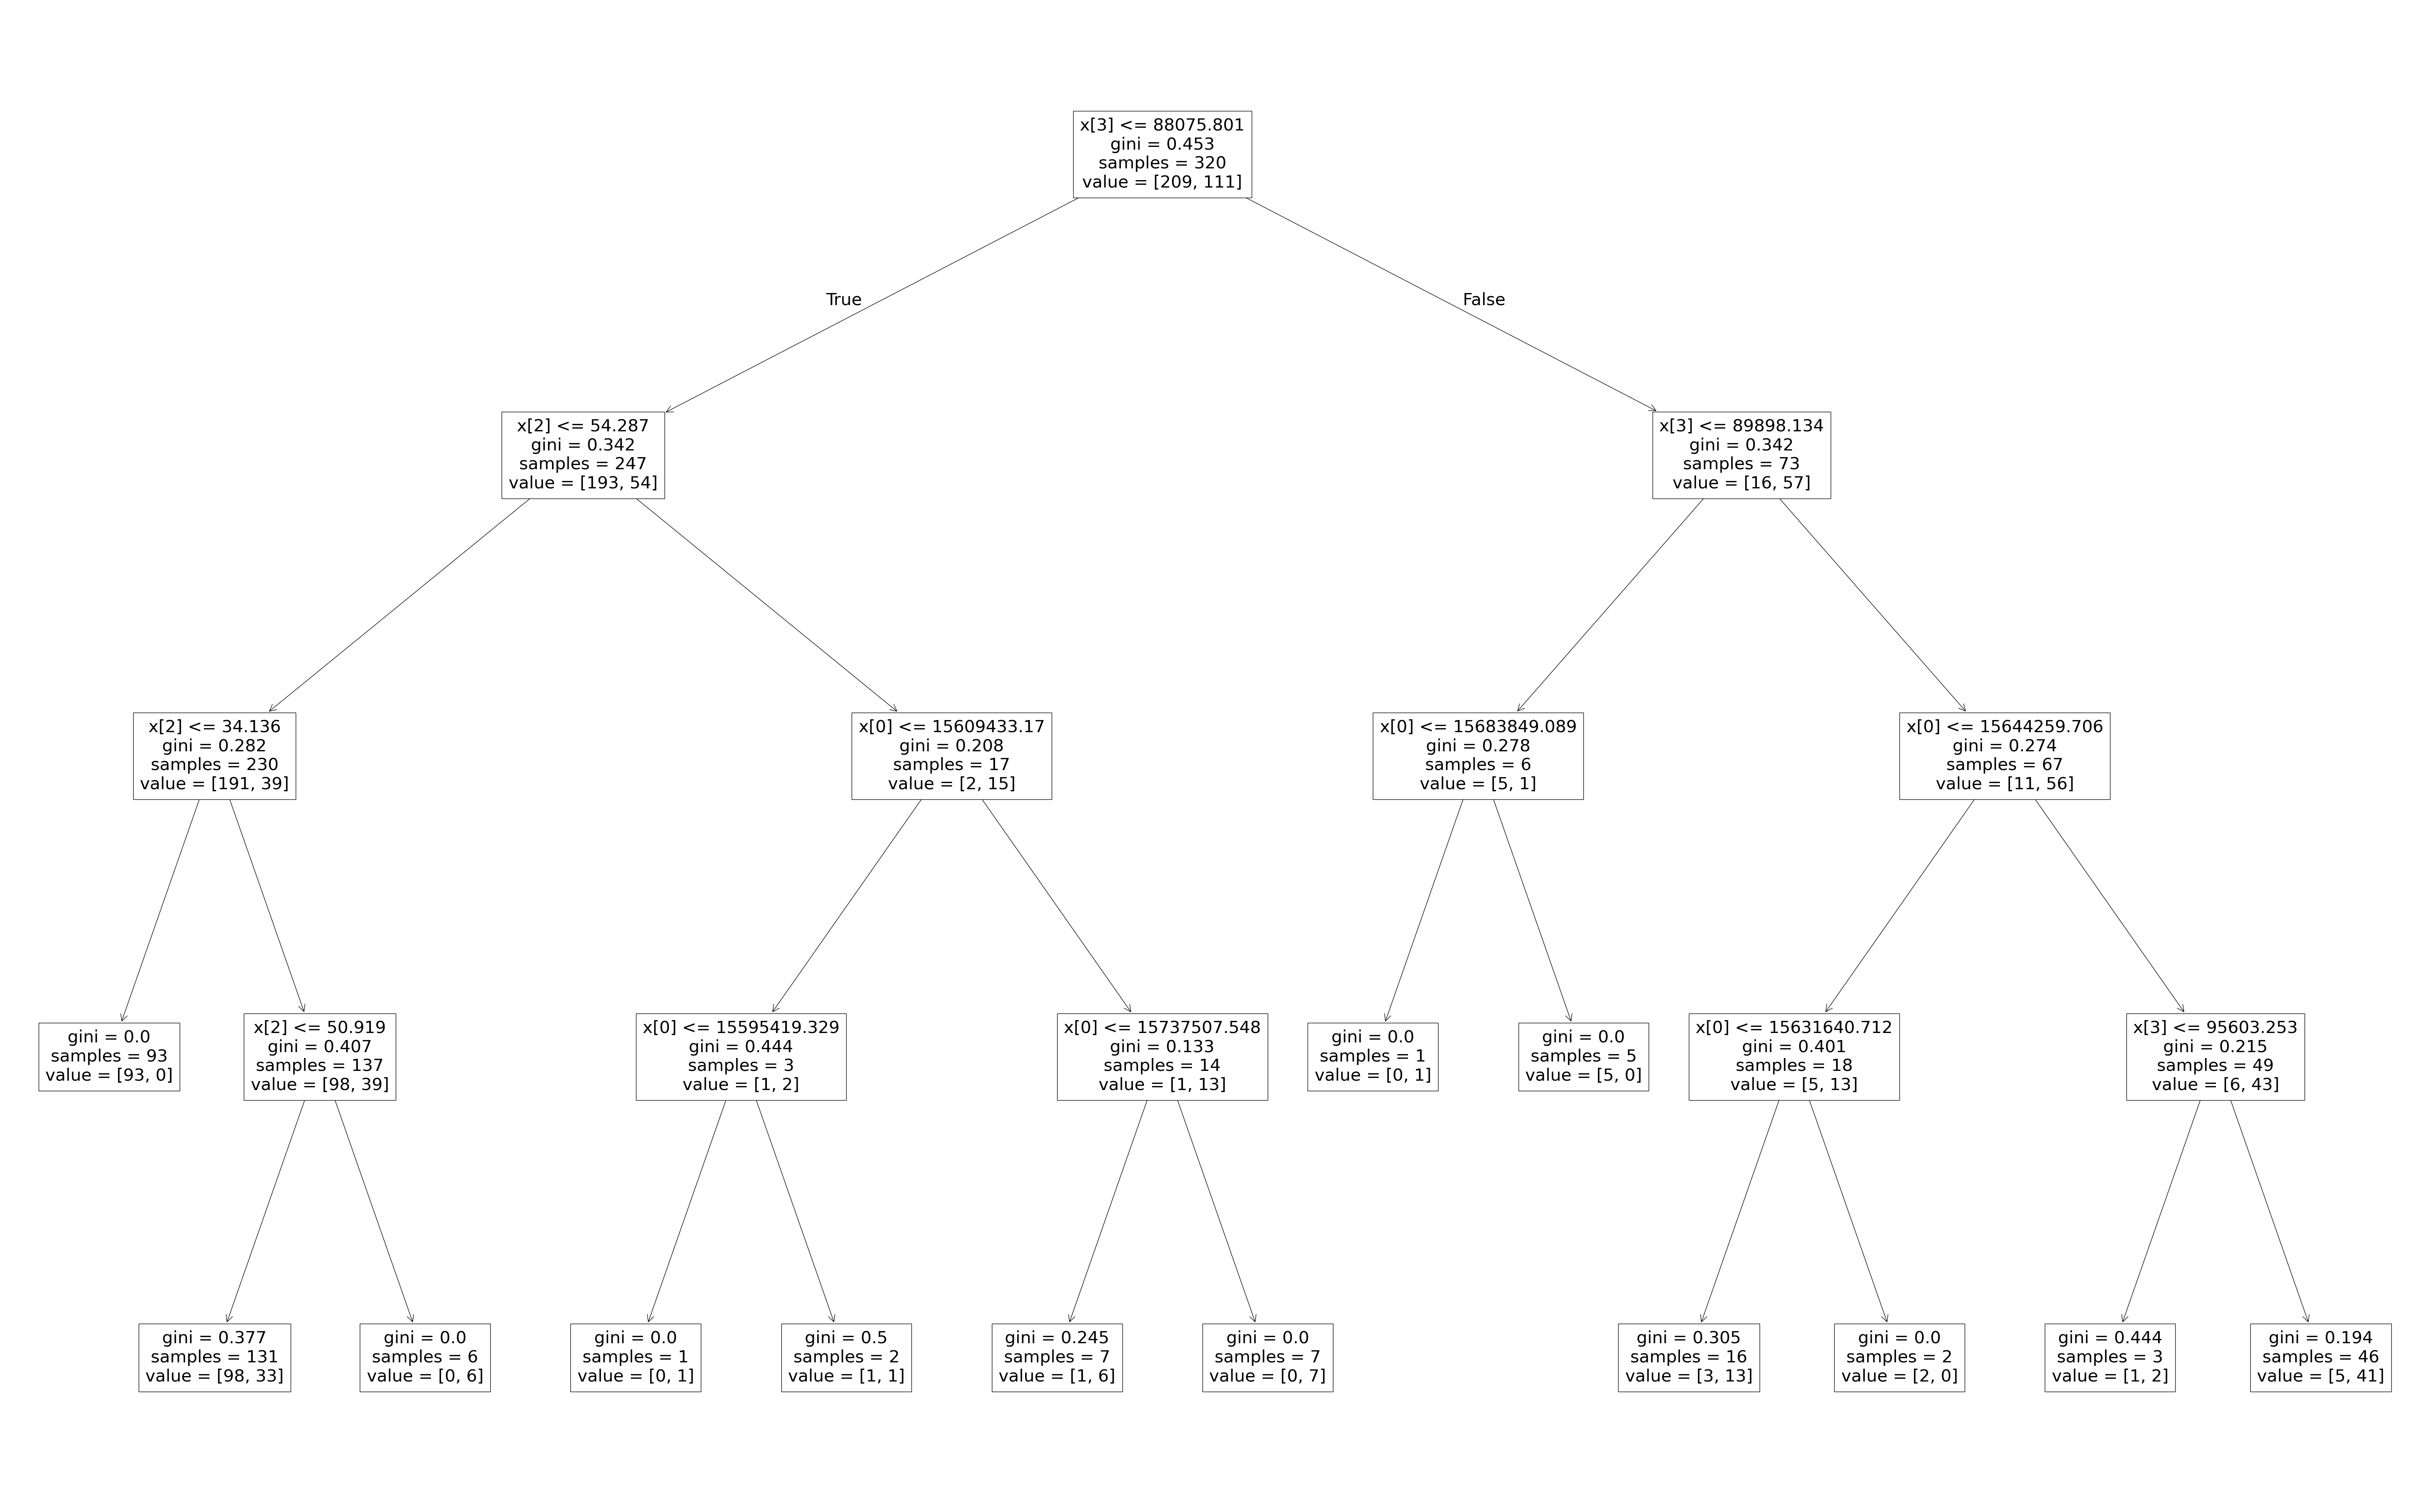

In [44]:
rcParams['figure.figsize'] = 80,50
plot_tree(dtc)

#predict

In [45]:
y_pred = dtc.predict(x_test)

#calculating error

In [46]:
mean_squared_error(y_pred,y_test)

0.175